In [1]:
import math

import numpy as np
import qiskit

import bosonic_qiskit

# Simulation of the Jaynes-Cummings Hamiltonian on a spin-boson hardware

The Hamiltonian is
$H=\omega_C a^\dagger a + \frac{\omega_A}{2}\sigma^z + \lambda \sigma^z (a^\dagger + a)$
</br></br>
We simulate the trotterized time evolution under this Hamiltonian  by implementing each term in $U_L=e^{-i \omega_C a^\dagger a t}$, $U_M=e^{-i \omega_A \sigma^z t/2}$ and $U_{LM}=e^{-i \lambda \sigma^z (a^\dagger + a) t}$ individually.

In [2]:
def eiht(circuit, boson, spin, omega_A, omega_C, lam, dt):
    # Appending each gate to the circuit
    
    # U_L = exp(-i omega_C a^\dag a t): rotation for the boson
    circuit.cv_r(-omega_C*dt,boson[0])

    # U_M = exp(-i omega_A \sigma_z/2 t): rotation for the spin
    circuit.rz(omega_A*dt,spin[0])

    # Implementing U_LM = exp(-i lambda \sigma_z (a^\dag +a) t) for the spin and the boson
    
    # Note that the controlled displacement gate uses sigma_z for the spin, not sigma_x, so we
    # rotate the spin's X component into Z 
    circuit.ry(-math.pi/2,spin[0])

    # U_LM' = exp(-i lambda \sigma_z (a^\dag +a) t), as controlled displacement for the spin and the boson
    circuit.cv_c_d(-1j*lam*dt,boson[0],spin[0])

    # Rotate back the spin's Z component into X
    circuit.ry(math.pi/2,spin[0])

    return circuit

def trotterise(circuit, boson, spin, omega_A, omega_C, lam, N, dt, sigmax, sigmaz):
    sigma_x_expectation = []
    sigma_z_expectation = []

    state, result, fock_counts = bosonic_qiskit.util.simulate(circuit)

    # Run Trotterised time evolution
    for i in range(N):
        print("step", i)

        #print(fock_counts)
        sigma_x_expectation.append(state.expectation_value(sigmax).real)
        sigma_z_expectation.append(state.expectation_value(sigmaz).real)

        # Implement the circuit, add gates for time evolution 
        eiht(circuit, boson, spin, omega_A, omega_C, lam, dt)

        # Run cirtuit -- starting from the initial state!!!  
        state, result, fock_counts = bosonic_qiskit.util.simulate(circuit)
        
    return sigma_x_expectation, sigma_z_expectation

In [5]:
# Define Hamiltonian parameters
omega_A = 1
omega_C = 1
lam = 0.1

# Define computational parameters 
t_tot = 2*np.pi/lam # total time 
N = 100 # number of Trotter time steps
dt = t_tot/N # timestep

# Cutoff of the qumode's Fock space: 2^num_qubits_per_qumode
num_qubits_per_qumode = 3

# Create new circuit
boson = bosonic_qiskit.QumodeRegister(num_qumodes=1, num_qubits_per_qumode=num_qubits_per_qumode)
spin = qiskit.QuantumRegister(1)
circuit = bosonic_qiskit.CVCircuit(boson,spin)

# Initialize state to the upper state of the spin
circuit.initialize([1, 0], spin)

# Define matrices of the observables
I_qumode = circuit.ops.get_eye(boson.cutoff).toarray()
sigmax = np.kron(np.array([[0, 1], [1, 0]]), I_qumode) # sigma_x of the spin
sigmaz = np.kron(np.array([[1, 0], [0, -1]]), I_qumode) # sigma_z of the spin

In [6]:
# Run circuit and collect observable trajectories
sigma_x_expectation, sigma_z_expectation = trotterise(circuit, boson, spin, omega_A, omega_C, lam, N, dt, sigmax, sigmaz)

step 0
step 1
step 2
step 3


/home/iren/quantum_algorithm/.venv/lib/python3.12/site-packages/scipy/sparse/_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csc_array is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


step 4
step 5
step 6
step 7
step 8
step 9
step 10
step 11
step 12
step 13
step 14
step 15
step 16
step 17
step 18
step 19
step 20
step 21
step 22
step 23
step 24
step 25
step 26
step 27
step 28
step 29
step 30
step 31
step 32
step 33
step 34
step 35
step 36
step 37
step 38
step 39
step 40
step 41
step 42
step 43
step 44
step 45
step 46
step 47
step 48
step 49
step 50
step 51
step 52
step 53
step 54
step 55
step 56
step 57
step 58
step 59
step 60
step 61
step 62
step 63
step 64
step 65
step 66
step 67
step 68
step 69
step 70
step 71
step 72
step 73
step 74
step 75
step 76
step 77
step 78
step 79
step 80
step 81
step 82
step 83
step 84
step 85
step 86
step 87
step 88
step 89
step 90
step 91
step 92
step 93
step 94
step 95
step 96
step 97
step 98
step 99


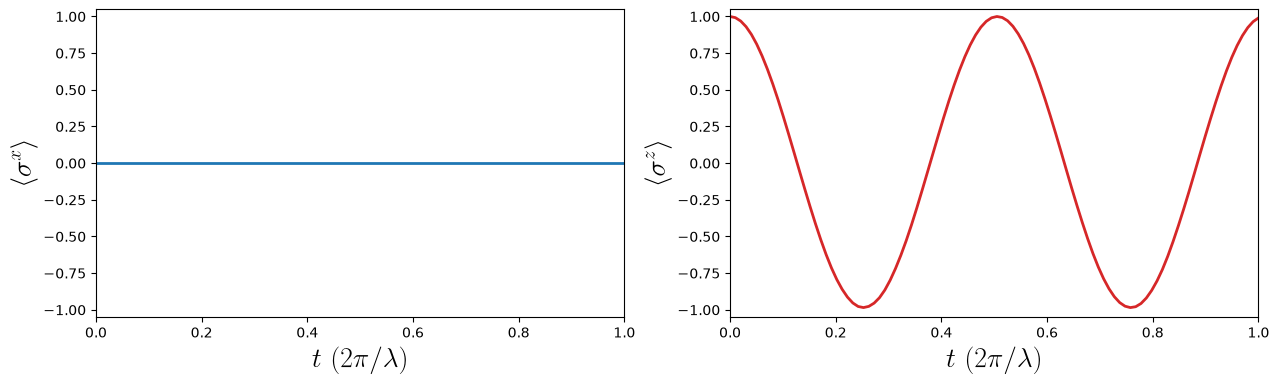

In [7]:
import matplotlib.pyplot as plt

fontsize = 20

tarray = np.linspace(0,t_tot,N)

plt.figure(figsize=(15,4))
plt.subplot(1,2,1)
plt.plot(tarray/(2*np.pi/lam),sigma_x_expectation,linewidth=2)
plt.ylabel(r'$\langle\sigma^x\rangle$',fontsize=fontsize,usetex=True);
plt.xlabel(r'$t$ $(2\pi/\lambda)$',fontsize=fontsize,usetex=True);
plt.xlim([0,1]);
plt.ylim([-1.05,1.05]);

plt.subplot(1,2,2)
plt.plot(tarray/(2*np.pi/lam),sigma_z_expectation,linewidth=2,color='tab:red')
plt.ylabel(r'$\langle\sigma^z\rangle$',fontsize=fontsize,usetex=True);
plt.xlabel(r'$t$ $(2\pi/\lambda)$',fontsize=fontsize,usetex=True);
plt.xlim([0,1]);
plt.ylim([-1.05,1.05]);